# Chest X-Ray Pneumonia Classifier
## Binary Classification with ResNet50 Transfer Learning

**Task:** Classify chest X-ray images as NORMAL or PNEUMONIA using transfer learning with ResNet50 pretrained on ImageNet.

**Dataset:** CoronaHack Chest X-Ray Dataset (Kaggle)

**Approach:** Two-phase transfer learning — frozen feature extraction followed by partial fine-tuning.

**Environment:** Designed to run on Google Colab (GPU recommended) or locally.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## 0. Google Colab Setup
Run this section **only on Google Colab**. It verifies the uploaded dataset and checks GPU availability.

**Prerequisite:** Upload the `archive/` folder to `/content/` in Colab before running.

If running locally, skip to Section 1.

In [ ]:
!ls -lh "/content/drive/MyDrive/archive.zip"

-rw------- 1 root root 1.2G Feb 17 19:02 /content/drive/MyDrive/archive.zip


In [ ]:
!unzip -q "/content/drive/MyDrive/archive.zip" -d "/content/"

replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0001-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0003-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0005-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0006-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0007-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0009-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test/IM-0010-0001.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /cont

In [ ]:
!ls /content/

archive				       Coronahack-Chest-XRay-Dataset
Chest_xray_Corona_dataset_Summary.csv  drive
Chest_xray_Corona_Metadata.csv	       sample_data


In [ ]:
  !mkdir -p /content/archive
  !mv /content/Chest_xray_Corona_Metadata.csv /content/archive/
  !mv /content/Chest_xray_Corona_dataset_Summary.csv /content/archive/
  !mv /content/Coronahack-Chest-XRay-Dataset /content/archive/

mv: cannot move '/content/Coronahack-Chest-XRay-Dataset' to '/content/archive/Coronahack-Chest-XRay-Dataset': Directory not empty


In [ ]:
!ls /content/archive/

Chest_xray_Corona_dataset_Summary.csv  Coronahack-Chest-XRay-Dataset
Chest_xray_Corona_Metadata.csv


In [ ]:
# ══════════════════════════════════════════════════════════════
# GOOGLE COLAB SETUP — skip this cell if running locally
# ══════════════════════════════════════════════════════════════
import os

# Detect if running in Colab
IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    print("Google Colab detected — verifying dataset...\n")

    # Verify uploaded archive folder structure
    DATA_ROOT = '/content/archive'
    expected_train = os.path.join(
        DATA_ROOT, 'Coronahack-Chest-XRay-Dataset',
        'Coronahack-Chest-XRay-Dataset', 'train'
    )
    expected_csv = os.path.join(DATA_ROOT, 'Chest_xray_Corona_Metadata.csv')

    assert os.path.isdir(expected_train), (
        f"Train dir not found at: {expected_train}\n"
        "Make sure you uploaded the archive/ folder to /content/"
    )
    assert os.path.isfile(expected_csv), (
        f"Metadata CSV not found at: {expected_csv}\n"
        "Make sure you uploaded the archive/ folder to /content/"
    )

    n_train = len(os.listdir(expected_train))
    print(f"Verification PASSED:")
    print(f"  - Train images: {n_train}")
    print(f"  - Metadata CSV: found")

    # Check GPU
    gpu_name = os.popen('nvidia-smi --query-gpu=name --format=csv,noheader 2>/dev/null').read().strip()
    if gpu_name:
        print(f"  - GPU: {gpu_name}")
    else:
        print("  - WARNING: No GPU detected (go to Runtime > Change runtime type > GPU)")

else:
    print("Not running in Google Colab — skipping Colab setup.")
    print("Ensure the dataset is in ./archive/ directory.")

Google Colab detected — verifying dataset...

Verification PASSED:
  - Train images: 5309
  - Metadata CSV: found
  - WARNING: No GPU detected (go to Runtime > Change runtime type > GPU)


In [ ]:
# ── Reproducibility seeds (set BEFORE importing TF) ──
import os
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import random
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(42)
np.random.seed(42)

import tensorflow as tf
tf.random.set_seed(42)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve,
    average_precision_score, f1_score, precision_score, recall_score
)

warnings.filterwarnings('ignore')

print(f"Python random seed: 42")
print(f"NumPy version:      {np.__version__}")
print(f"TensorFlow version: {tf.__version__}")
print(f"Pandas version:     {pd.__version__}")

Python random seed: 42
NumPy version:      2.0.2
TensorFlow version: 2.19.0
Pandas version:     2.2.2


In [ ]:
# ── GPU Detection & Configuration ──
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPUs detected: {len(gpus)}")
    for gpu in gpus:
        print(f"  - {gpu.name}")
    # Enable mixed precision for supported GPUs
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision enabled (float16)")
    BATCH_SIZE = 32
else:
    print("No GPU detected — training will run on CPU")
    BATCH_SIZE = 16

print(f"Batch size: {BATCH_SIZE}")

No GPU detected — training will run on CPU
Batch size: 16


In [ ]:
# ── Paths & Output Directories ──
# Auto-detect environment: Colab uses /content, local uses current dir
try:
    import google.colab
    BASE_DIR = Path('/content')
except ImportError:
    BASE_DIR = Path('.')

DATA_DIR = BASE_DIR / 'archive'
IMAGES_TRAIN_DIR = DATA_DIR / 'Coronahack-Chest-XRay-Dataset' / 'Coronahack-Chest-XRay-Dataset' / 'train'
IMAGES_TEST_DIR = DATA_DIR / 'Coronahack-Chest-XRay-Dataset' / 'Coronahack-Chest-XRay-Dataset' / 'test'
METADATA_PATH = DATA_DIR / 'Chest_xray_Corona_Metadata.csv'

OUTPUT_DIR = BASE_DIR / 'outputs'
for subdir in ['model', 'checkpoints', 'plots', 'metrics']:
    (OUTPUT_DIR / subdir).mkdir(parents=True, exist_ok=True)

# ── Constants ──
IMG_SIZE = (224, 224)
IMG_SHAPE = (224, 224, 3)
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

print(f"Environment:      {'Google Colab' if str(BASE_DIR) == '/content' else 'Local'}")
print(f"Train images dir: {IMAGES_TRAIN_DIR}")
print(f"Test images dir:  {IMAGES_TEST_DIR}")
print(f"Metadata CSV:     {METADATA_PATH}")
print(f"Output directory:  {OUTPUT_DIR}")

Environment:      Google Colab
Train images dir: /content/archive/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/train
Test images dir:  /content/archive/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test
Metadata CSV:     /content/archive/Chest_xray_Corona_Metadata.csv
Output directory:  /content/outputs


In [ ]:
# ── Paths & Output Directories ──
BASE_DIR = Path('.')
DATA_DIR = BASE_DIR / 'archive'
IMAGES_TRAIN_DIR = DATA_DIR / 'Coronahack-Chest-XRay-Dataset' / 'Coronahack-Chest-XRay-Dataset' / 'train'
IMAGES_TEST_DIR = DATA_DIR / 'Coronahack-Chest-XRay-Dataset' / 'Coronahack-Chest-XRay-Dataset' / 'test'
METADATA_PATH = DATA_DIR / 'Chest_xray_Corona_Metadata.csv'

OUTPUT_DIR = BASE_DIR / 'outputs'
for subdir in ['model', 'checkpoints', 'plots', 'metrics']:
    (OUTPUT_DIR / subdir).mkdir(parents=True, exist_ok=True)

# ── Constants ──
IMG_SIZE = (224, 224)
IMG_SHAPE = (224, 224, 3)
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

print(f"Train images dir: {IMAGES_TRAIN_DIR}")
print(f"Test images dir:  {IMAGES_TEST_DIR}")
print(f"Metadata CSV:     {METADATA_PATH}")
print(f"Output directory:  {OUTPUT_DIR}")

Train images dir: archive/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/train
Test images dir:  archive/Coronahack-Chest-XRay-Dataset/Coronahack-Chest-XRay-Dataset/test
Metadata CSV:     archive/Chest_xray_Corona_Metadata.csv
Output directory:  outputs


---
## 2. Dataset Loading & Exploration

In [ ]:
# ── Load metadata ──
meta = pd.read_csv(METADATA_PATH)
print(f"Metadata shape: {meta.shape}")
print(f"\nColumns: {list(meta.columns)}")
print(f"\nLabel distribution:\n{meta['Label'].value_counts()}")
print(f"\nDataset type distribution:\n{meta['Dataset_type'].value_counts()}")
meta.head()

Metadata shape: (5910, 6)

Columns: ['Unnamed: 0', 'X_ray_image_name', 'Label', 'Dataset_type', 'Label_2_Virus_category', 'Label_1_Virus_category']

Label distribution:
Label
Pnemonia    4334
Normal      1576
Name: count, dtype: int64

Dataset type distribution:
Dataset_type
TRAIN    5286
TEST      624
Name: count, dtype: int64


,Unnamed: 0,X_ray_image_name,Label,Dataset_type,Label_2_Virus_category,Label_1_Virus_category
0,0,IM-0128-0001.jpeg,Normal,TRAIN,NaN,NaN
1,1,IM-0127-0001.jpeg,Normal,TRAIN,NaN,NaN
2,2,IM-0125-0001.jpeg,Normal,TRAIN,NaN,NaN
3,3,IM-0122-0001.jpeg,Normal,TRAIN,NaN,NaN
4,4,IM-0119-0001.jpeg,Normal,TRAIN,NaN,NaN


In [ ]:
# ── Map labels to binary (Normal=0, Pnemonia=1) ──
# Note: the dataset uses the spelling "Pnemonia" (Kaggle typo)
meta['label_binary'] = (meta['Label'] == 'Pnemonia').astype(int)

# ── Split metadata by dataset type ──
meta_train_full = meta[meta['Dataset_type'] == 'TRAIN'].copy()
meta_test = meta[meta['Dataset_type'] == 'TEST'].copy()

# ── Build full file paths and verify files exist ──
meta_train_full['filepath'] = meta_train_full['X_ray_image_name'].apply(
    lambda x: str(IMAGES_TRAIN_DIR / x)
)
meta_test['filepath'] = meta_test['X_ray_image_name'].apply(
    lambda x: str(IMAGES_TEST_DIR / x)
)

# Verify files exist
train_exists = meta_train_full['filepath'].apply(os.path.isfile)
test_exists = meta_test['filepath'].apply(os.path.isfile)

print(f"Train files found: {train_exists.sum()} / {len(meta_train_full)}")
print(f"Test files found:  {test_exists.sum()} / {len(meta_test)}")

# Keep only rows with existing files
meta_train_full = meta_train_full[train_exists].reset_index(drop=True)
meta_test = meta_test[test_exists].reset_index(drop=True)

print(f"\nTrain set (full): {len(meta_train_full)} images")
print(f"Test set:          {len(meta_test)} images")

Train files found: 5286 / 5286
Test files found:  624 / 624

Train set (full): 5286 images
Test set:          624 images


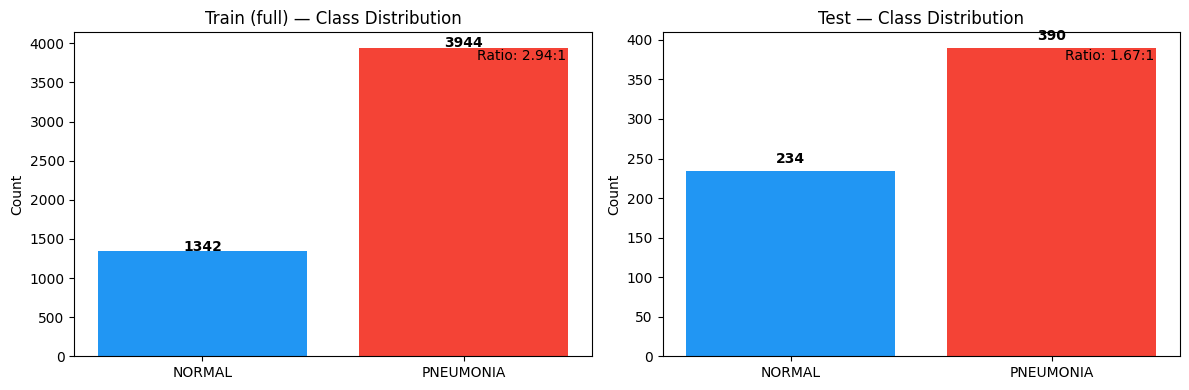

Saved: outputs/plots/class_distribution.png


In [ ]:
# ── Class distribution visualization ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

label_names = {0: 'NORMAL', 1: 'PNEUMONIA'}

for ax, (name, df) in zip(axes, [('Train (full)', meta_train_full), ('Test', meta_test)]):
    counts = df['label_binary'].value_counts().sort_index()
    bars = ax.bar(
        [label_names[i] for i in counts.index],
        counts.values,
        color=['#2196F3', '#F44336']
    )
    for bar, count in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(count), ha='center', fontweight='bold')
    ax.set_title(f'{name} — Class Distribution')
    ax.set_ylabel('Count')
    total = counts.sum()
    ratio = counts.values[1] / counts.values[0] if len(counts) == 2 else 0
    ax.text(0.95, 0.95, f'Ratio: {ratio:.2f}:1',
            transform=ax.transAxes, ha='right', va='top', fontsize=10)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/plots/class_distribution.png")

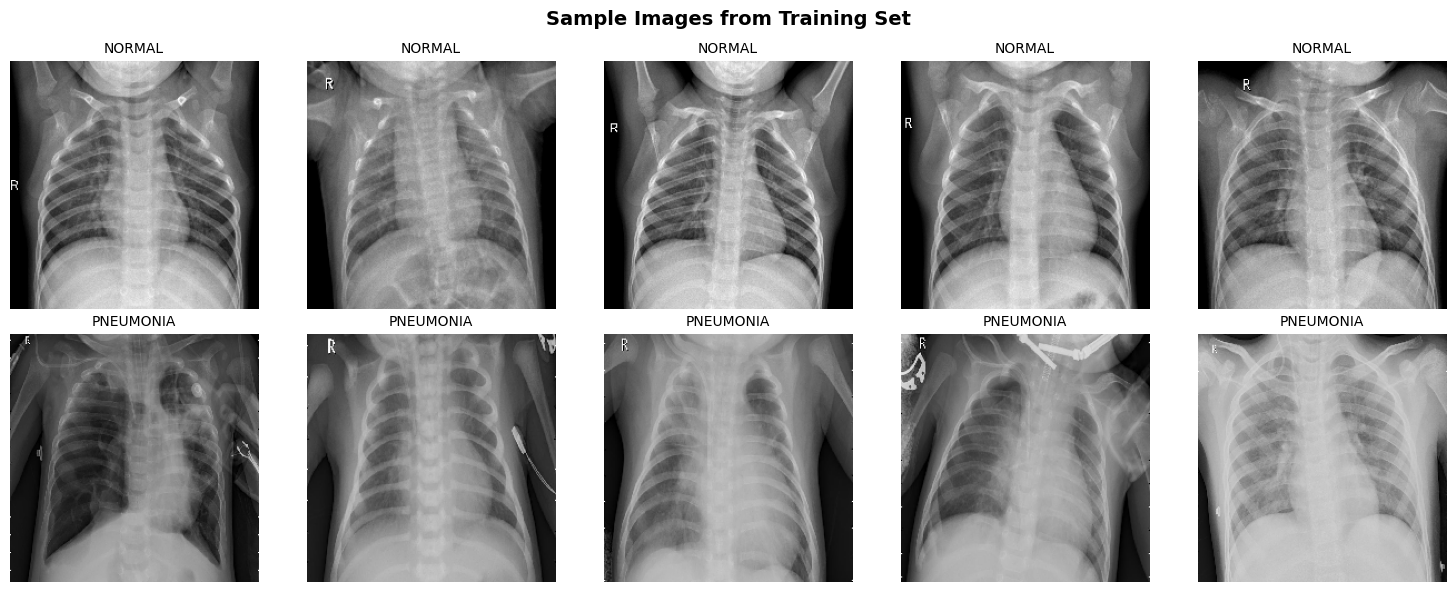

Saved: outputs/plots/sample_images.png


In [ ]:
# ── Sample images ──
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, label in enumerate([0, 1]):
    samples = meta_train_full[meta_train_full['label_binary'] == label].sample(5, random_state=SEED)
    for col, (_, row_data) in enumerate(samples.iterrows()):
        img = tf.keras.utils.load_img(row_data['filepath'], target_size=IMG_SIZE)
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(label_names[label], fontsize=10)
        axes[row, col].axis('off')

plt.suptitle('Sample Images from Training Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/plots/sample_images.png")

---
## 3. Train/Validation Split

In [ ]:
# ── Stratified split: 85% train / 15% validation ──
train_df, val_df = train_test_split(
    meta_train_full,
    test_size=0.15,
    random_state=SEED,
    stratify=meta_train_full['label_binary']
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = meta_test.reset_index(drop=True)

# ── Verify no data leakage ──
train_files = set(train_df['X_ray_image_name'])
val_files = set(val_df['X_ray_image_name'])
test_files = set(test_df['X_ray_image_name'])

assert len(train_files & val_files) == 0, "LEAKAGE: train/val overlap!"
assert len(train_files & test_files) == 0, "LEAKAGE: train/test overlap!"
assert len(val_files & test_files) == 0, "LEAKAGE: val/test overlap!"
print("Data leakage check PASSED — no overlaps between splits.")

# ── Report split sizes ──
print(f"\n{'Split':<12} {'Normal':>8} {'Pneumonia':>10} {'Total':>8} {'Pneu%':>8}")
print('-' * 50)
for name, df in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    n_normal = (df['label_binary'] == 0).sum()
    n_pneum = (df['label_binary'] == 1).sum()
    total = len(df)
    pct = n_pneum / total * 100
    print(f"{name:<12} {n_normal:>8} {n_pneum:>10} {total:>8} {pct:>7.1f}%")

Data leakage check PASSED — no overlaps between splits.

Split          Normal  Pneumonia    Total    Pneu%
--------------------------------------------------
Train            1141       3352     4493    74.6%
Validation        201        592      793    74.7%
Test              234        390      624    62.5%


In [ ]:
# ── Compute class weights for imbalance handling ──
n_total = len(train_df)
n_normal = (train_df['label_binary'] == 0).sum()
n_pneumonia = (train_df['label_binary'] == 1).sum()

class_weight = {
    0: n_total / (2 * n_normal),
    1: n_total / (2 * n_pneumonia)
}

print(f"Class weights:")
print(f"  NORMAL (0):    {class_weight[0]:.4f}")
print(f"  PNEUMONIA (1): {class_weight[1]:.4f}")

Class weights:
  NORMAL (0):    1.9689
  PNEUMONIA (1): 0.6702


---
## 4. Data Pipeline (tf.data)

In [ ]:
# ── Image loading & preprocessing function ──
def load_and_preprocess(filepath, label):
    """Load image from path, decode, resize, and apply ResNet50 preprocessing."""
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)  # Force 3 channels (grayscale → RGB)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.resnet50.preprocess_input(img)
    return img, label


def build_dataset(dataframe, shuffle=False, augment=False):
    """Build a tf.data.Dataset from a DataFrame with filepath and label_binary columns."""
    filepaths = dataframe['filepath'].values
    labels = dataframe['label_binary'].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(buffer_size=1000, seed=SEED)

    ds = ds.batch(BATCH_SIZE)

    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)

    ds = ds.prefetch(AUTOTUNE)
    return ds


print("Dataset builder functions defined.")

Dataset builder functions defined.


In [ ]:
# ── Data augmentation layer (training only) ──
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomZoom((-0.05, 0.05), seed=SEED),
    tf.keras.layers.RandomBrightness(0.1, seed=SEED),
    tf.keras.layers.RandomContrast(0.1, seed=SEED),
], name='data_augmentation')

print("Data augmentation pipeline:")
for layer in data_augmentation.layers:
    print(f"  - {layer.name}")

Data augmentation pipeline:
  - random_flip_1
  - random_rotation_1
  - random_zoom_1
  - random_brightness_1
  - random_contrast_1


In [ ]:
# ── Build datasets ──
BATCH_SIZE = 32
train_ds = build_dataset(train_df, shuffle=True, augment=True)
val_ds = build_dataset(val_df, shuffle=False, augment=False)
test_ds = build_dataset(test_df, shuffle=False, augment=False)

# Verify shapes
for images, labels in train_ds.take(1):
    print(f"Train batch — images: {images.shape}, labels: {labels.shape}")
    print(f"Pixel range: [{images.numpy().min():.1f}, {images.numpy().max():.1f}]")
    print(f"Label values in batch: {np.unique(labels.numpy())}")

Train batch — images: (32, 224, 224, 3), labels: (32,)
Pixel range: [0.0, 175.4]
Label values in batch: [0. 1.]


---
## 5. Model Construction

In [ ]:
# ── Build model with ResNet50 base + custom classification head ──
def build_model():
    # Base model: ResNet50 pretrained on ImageNet
    base_model = tf.keras.applications.ResNet50(
        include_top=False,
        weights='imagenet',
        input_shape=IMG_SHAPE
    )
    base_model.trainable = False  # Freeze all base layers

    # Custom classification head
    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5, seed=SEED)(x)
    # Use float32 output for numerical stability (important with mixed precision)
    outputs = tf.keras.layers.Dense(1, activation='sigmoid', dtype='float32')(x)

    model = tf.keras.Model(inputs, outputs, name='resnet50_pneumonia')
    return model, base_model


model, base_model = build_model()

total_params = model.count_params()
trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
frozen_params = total_params - trainable_params

print(f"Total parameters:     {total_params:>12,}")
print(f"Trainable parameters: {trainable_params:>12,}")
print(f"Frozen parameters:    {frozen_params:>12,}")
print(f"\nBase model layers: {len(base_model.layers)}")
model.summary(show_trainable=True)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Total parameters:       24,120,705
Trainable parameters:      528,897
Frozen parameters:      23,591,808

Base model layers: 175


Model: "resnet50_pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_2 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ batch_normalization         │ (None, 2048)          │      8,192 │   Y   │
│ (BatchNormalization)        │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 256)           │    524,544 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 256)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_1 (Dense)             │ (None, 1)             │        257 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 24,120,705 (92.01 MB)

 Trainable params: 528,897 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

---
## 6. Phase 1 — Feature Extraction (Frozen Base)

In [ ]:
# ── Compile for Phase 1 ──
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
    ]
)

# ── Callbacks ──
callbacks_phase1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / 'checkpoints' / 'best_model_phase1.keras'),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
]

print("Phase 1 configuration:")
print(f"  Optimizer:     Adam (lr=1e-3)")
print(f"  Loss:          BinaryCrossentropy")
print(f"  Base model:    FROZEN")
print(f"  Class weights: {class_weight}")

Phase 1 configuration:
  Optimizer:     Adam (lr=1e-3)
  Loss:          BinaryCrossentropy
  Base model:    FROZEN
  Class weights: {0: np.float64(1.9688869412795793), 1: np.float64(0.6701968973747017)}


In [ ]:
# ── Train Phase 1 ──
import time

print("="*60)
print("PHASE 1: Feature Extraction (Frozen Base)")
print("="*60)

t0 = time.time()

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weight,
    callbacks=callbacks_phase1,
    verbose=1
)

phase1_time = time.time() - t0
print(f"\nPhase 1 completed in {phase1_time:.1f}s ({phase1_time/60:.1f} min)")
print(f"Epochs trained: {len(history_phase1.history['loss'])}")

PHASE 1: Feature Extraction (Frozen Base)
Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8485 - auc: 0.9364 - loss: 0.4250 - precision: 0.9664 - recall: 0.8259
Epoch 1: val_loss improved from inf to 0.70354, saving model to outputs/checkpoints/best_model_phase1.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 1114s 8s/step - accuracy: 0.8489 - auc: 0.9366 - loss: 0.4242 - precision: 0.9665 - recall: 0.8264 - val_accuracy: 0.7907 - val_auc: 0.9401 - val_loss: 0.7035 - val_precision: 0.7810 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9365 - auc: 0.9830 - loss: 0.1864 - precision: 0.9796 - recall: 0.9364
Epoch 2: val_loss improved from 0.70354 to 0.26911, saving model to outputs/checkpoints/best_model_phase1.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 1037s 7s/step - accuracy: 0.9365 - auc: 0.9830 - loss: 0.1866 - precision: 0.9796 - recall: 0.9364 - val_accuracy: 0.9206 - val_auc: 0.9640 - val_loss: 0.2691 - val_precision: 0.91

---
## 7. Phase 2 — Fine-Tuning (Partial Unfreeze)

In [ ]:
# ── Unfreeze conv5_block (last residual block) ──
base_model.trainable = True

# Find the index of conv5_block1
fine_tune_at = None
for i, layer in enumerate(base_model.layers):
    if layer.name == 'conv5_block1_1_conv':
        fine_tune_at = i
        break

assert fine_tune_at is not None, "Could not find conv5_block1_1_conv layer"
print(f"Unfreezing from layer {fine_tune_at} ({base_model.layers[fine_tune_at].name})")
print(f"Total base layers: {len(base_model.layers)}")
print(f"Frozen layers:     {fine_tune_at}")
print(f"Unfrozen layers:   {len(base_model.layers) - fine_tune_at}")

# Freeze all layers before conv5_block
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Report new parameter counts
trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
print(f"\nTrainable parameters after unfreeze: {trainable_params:,}")

Unfreezing from layer 143 (conv5_block1_1_conv)
Total base layers: 175
Frozen layers:     143
Unfrozen layers:   32

Trainable parameters after unfreeze: 15,504,897


In [ ]:
# ── Recompile with lower learning rate ──
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
    ]
)

callbacks_phase2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / 'checkpoints' / 'best_model_phase2.keras'),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
]

print("Phase 2 configuration:")
print(f"  Optimizer:     Adam (lr=1e-5)")
print(f"  Base model:    PARTIALLY UNFROZEN (conv5_block+)")
print(f"  Max epochs:    30")

Phase 2 configuration:
  Optimizer:     Adam (lr=1e-5)
  Base model:    PARTIALLY UNFROZEN (conv5_block+)
  Max epochs:    30


In [55]:
# ── Train Phase 2 ──
print("="*60)
print("PHASE 2: Fine-Tuning (conv5_block unfrozen)")
print("="*60)

t0 = time.time()

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=callbacks_phase2,
    verbose=1
)

phase2_time = time.time() - t0
print(f"\nPhase 2 completed in {phase2_time:.1f}s ({phase2_time/60:.1f} min)")
print(f"Epochs trained: {len(history_phase2.history['loss'])}")

PHASE 2: Fine-Tuning (conv5_block unfrozen)
Epoch 1/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9444 - auc: 0.9895 - loss: 0.1301 - precision: 0.9907 - recall: 0.9349
Epoch 1: val_loss improved from inf to 0.19845, saving model to outputs/checkpoints/best_model_phase2.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 1466s 10s/step - accuracy: 0.9445 - auc: 0.9895 - loss: 0.1301 - precision: 0.9907 - recall: 0.9350 - val_accuracy: 0.9433 - val_auc: 0.9770 - val_loss: 0.1984 - val_precision: 0.9536 - val_recall: 0.9713 - learning_rate: 1.0000e-05
Epoch 2/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9571 - auc: 0.9935 - loss: 0.1022 - precision: 0.9930 - recall: 0.9496
Epoch 2: val_loss did not improve from 0.19845
141/141 ━━━━━━━━━━━━━━━━━━━━ 1457s 10s/step - accuracy: 0.9572 - auc: 0.9934 - loss: 0.1022 - precision: 0.9930 - recall: 0.9496 - val_accuracy: 0.9382 - val_auc: 0.9706 - val_loss: 0.2256 - val_precision: 0.9705 - val_recall: 0.9459 - learning_rate: 1.0000e-05
Epoch

---
## 8. Training Curves

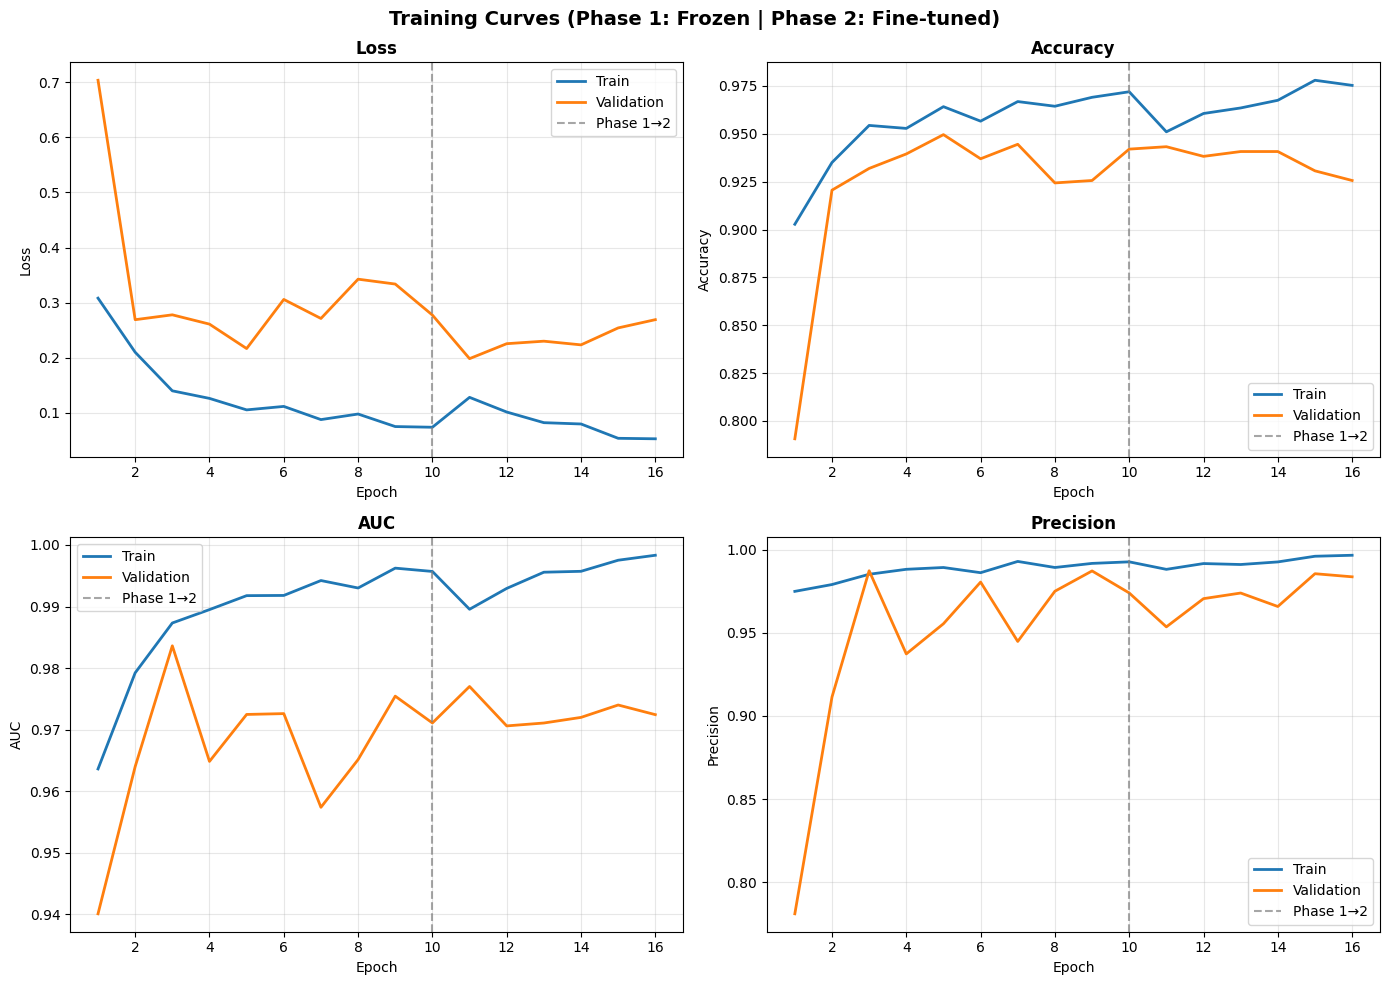

Saved: outputs/plots/training_curves.png


In [56]:
# ── Combine histories from both phases ──
def combine_histories(h1, h2):
    """Combine two Keras history objects into a single dict."""
    combined = {}
    for key in h1.history:
        combined[key] = h1.history[key] + h2.history[key]
    return combined

full_history = combine_histories(history_phase1, history_phase2)
phase1_epochs = len(history_phase1.history['loss'])
total_epochs = len(full_history['loss'])

# ── Plot training curves ──
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics_to_plot = [
    ('loss', 'val_loss', 'Loss'),
    ('accuracy', 'val_accuracy', 'Accuracy'),
    ('auc', 'val_auc', 'AUC'),
    ('precision', 'val_precision', 'Precision'),
]

for ax, (train_key, val_key, title) in zip(axes.flat, metrics_to_plot):
    epochs_range = range(1, total_epochs + 1)
    ax.plot(epochs_range, full_history[train_key], label='Train', linewidth=2)
    ax.plot(epochs_range, full_history[val_key], label='Validation', linewidth=2)
    ax.axvline(x=phase1_epochs, color='gray', linestyle='--', alpha=0.7, label='Phase 1→2')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Training Curves (Phase 1: Frozen | Phase 2: Fine-tuned)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/plots/training_curves.png")

---
## 9. Test Set Evaluation

In [58]:
# ── Generate predictions on test set ──
print("Generating predictions on test set...")
y_pred_proba = model.predict(test_ds, verbose=1).flatten()
y_pred = (y_pred_proba >= 0.5).astype(int)
y_true = test_df['label_binary'].values

print(f"\nTest samples:    {len(y_true)}")
print(f"Predictions >0.5: {y_pred.sum()} PNEUMONIA, {(1-y_pred).sum()} NORMAL")
print(f"Ground truth:     {(y_true==1).sum()} PNEUMONIA, {(y_true==0).sum()} NORMAL")

Generating predictions on test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 156s 7s/step

Test samples:    624
Predictions >0.5: 507 PNEUMONIA, 117 NORMAL
Ground truth:     390 PNEUMONIA, 234 NORMAL


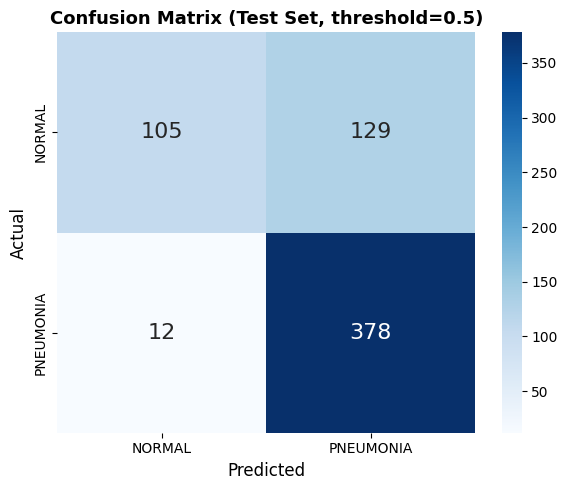

Saved: outputs/plots/confusion_matrix.png


In [59]:
# ── Confusion Matrix ──
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'],
            ax=ax, annot_kws={'size': 16})
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix (Test Set, threshold=0.5)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/plots/confusion_matrix.png")

In [60]:
# ── Classification Report ──
report_str = classification_report(
    y_true, y_pred,
    target_names=['NORMAL', 'PNEUMONIA'],
    digits=4
)
print("Classification Report (threshold=0.5):")
print(report_str)

# Save as JSON
report_dict = classification_report(
    y_true, y_pred,
    target_names=['NORMAL', 'PNEUMONIA'],
    output_dict=True
)
with open(OUTPUT_DIR / 'metrics' / 'classification_report.json', 'w') as f:
    json.dump(report_dict, f, indent=2)
print("Saved: outputs/metrics/classification_report.json")

Classification Report (threshold=0.5):
              precision    recall  f1-score   support

      NORMAL     0.8974    0.4487    0.5983       234
   PNEUMONIA     0.7456    0.9692    0.8428       390

    accuracy                         0.7740       624
   macro avg     0.8215    0.7090    0.7205       624
weighted avg     0.8025    0.7740    0.7511       624

Saved: outputs/metrics/classification_report.json


---
## 10. ROC & Precision-Recall Curves

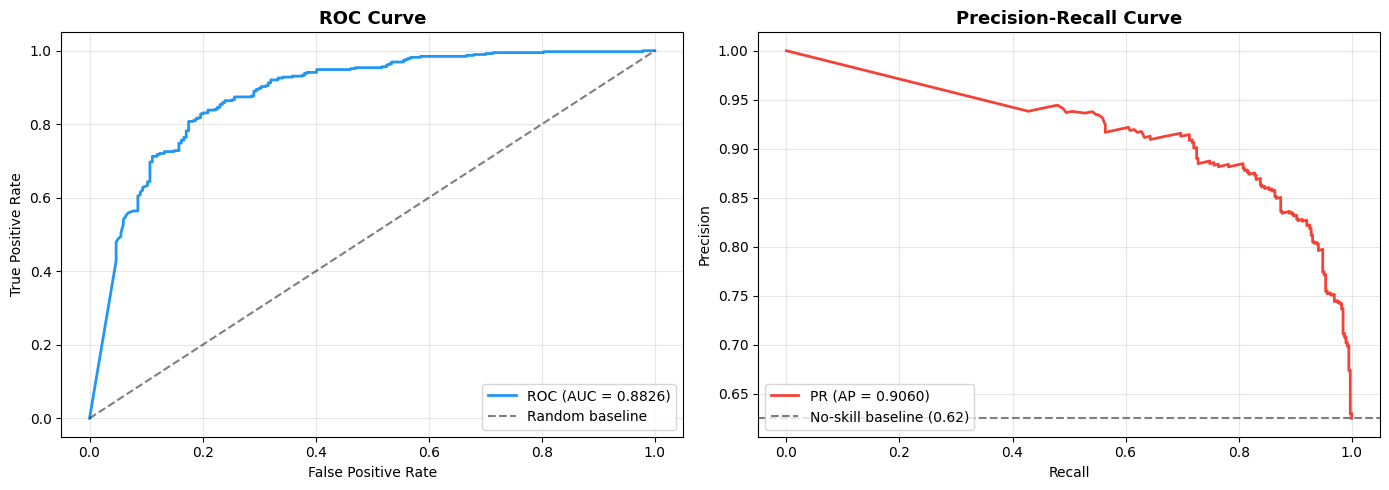

ROC-AUC: 0.8826
PR-AUC:  0.9060
Saved: outputs/plots/roc_pr_curves.png


In [61]:
# ── ROC Curve ──
fpr, tpr, roc_thresholds = roc_curve(y_true, y_pred_proba)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC
axes[0].plot(fpr, tpr, color='#2196F3', linewidth=2, label=f'ROC (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random baseline')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# Precision-Recall
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_true, y_pred_proba)
pr_auc = average_precision_score(y_true, y_pred_proba)
prevalence = y_true.mean()

axes[1].plot(recall_curve, precision_curve, color='#F44336', linewidth=2,
             label=f'PR (AP = {pr_auc:.4f})')
axes[1].axhline(y=prevalence, color='k', linestyle='--', alpha=0.5,
                label=f'No-skill baseline ({prevalence:.2f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}")
print("Saved: outputs/plots/roc_pr_curves.png")

---
## 11. Threshold Analysis

In [62]:
# ── Evaluate at multiple thresholds ──
thresholds = [0.3, 0.5, 0.7]
threshold_results = []

print(f"{'Threshold':>10} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print('-' * 55)

for thresh in thresholds:
    y_t = (y_pred_proba >= thresh).astype(int)
    acc = (y_t == y_true).mean()
    prec = precision_score(y_true, y_t, zero_division=0)
    rec = recall_score(y_true, y_t)
    f1 = f1_score(y_true, y_t)

    threshold_results.append({
        'threshold': thresh,
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'f1_score': round(f1, 4)
    })
    print(f"{thresh:>10.1f} {acc:>10.4f} {prec:>10.4f} {rec:>10.4f} {f1:>10.4f}")

print("\nClinical context:")
print("  - Threshold 0.3: High recall (fewer missed pneumonia cases) — suitable for screening")
print("  - Threshold 0.5: Balanced precision/recall — general purpose")
print("  - Threshold 0.7: High precision (fewer false alarms) — suitable for confirmation")

 Threshold   Accuracy  Precision     Recall         F1
-------------------------------------------------------
       0.3     0.7692     0.7365     0.9821     0.8418
       0.5     0.7740     0.7456     0.9692     0.8428
       0.7     0.7772     0.7525     0.9590     0.8433

Clinical context:
  - Threshold 0.3: High recall (fewer missed pneumonia cases) — suitable for screening
  - Threshold 0.5: Balanced precision/recall — general purpose
  - Threshold 0.7: High precision (fewer false alarms) — suitable for confirmation


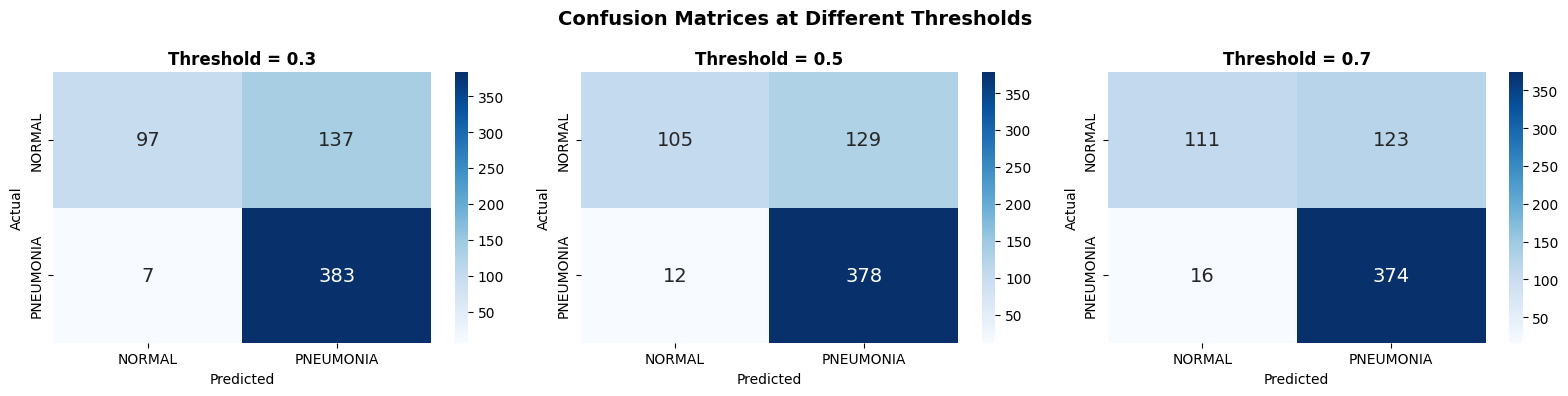

Saved: outputs/plots/threshold_comparison.png


In [63]:
# ── Confusion matrices at each threshold ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, thresh in zip(axes, thresholds):
    y_t = (y_pred_proba >= thresh).astype(int)
    cm_t = confusion_matrix(y_true, y_t)
    sns.heatmap(cm_t, annot=True, fmt='d', cmap='Blues',
                xticklabels=['NORMAL', 'PNEUMONIA'],
                yticklabels=['NORMAL', 'PNEUMONIA'],
                ax=ax, annot_kws={'size': 14})
    ax.set_title(f'Threshold = {thresh}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices at Different Thresholds', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'threshold_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/plots/threshold_comparison.png")

---
## 12. Export Artifacts

In [64]:
# ── Save final model ──
model_path = OUTPUT_DIR / 'model' / 'resnet50_pneumonia_classifier.keras'
model.save(model_path)
print(f"Model saved: {model_path}")

Model saved: outputs/model/resnet50_pneumonia_classifier.keras


In [65]:
# ── Save training history ──
history_df = pd.DataFrame(full_history)
history_df.index.name = 'epoch'
history_df.to_csv(OUTPUT_DIR / 'metrics' / 'training_history.csv')
print(f"Training history saved: outputs/metrics/training_history.csv")

# ── Save threshold analysis ──
with open(OUTPUT_DIR / 'metrics' / 'threshold_analysis.json', 'w') as f:
    json.dump({
        'roc_auc': round(roc_auc, 4),
        'pr_auc': round(pr_auc, 4),
        'thresholds': threshold_results,
        'phase1_epochs': phase1_epochs,
        'phase2_epochs': len(history_phase2.history['loss']),
        'total_epochs': total_epochs,
        'phase1_time_seconds': round(phase1_time, 1),
        'phase2_time_seconds': round(phase2_time, 1),
    }, f, indent=2)
print(f"Threshold analysis saved: outputs/metrics/threshold_analysis.json")

Training history saved: outputs/metrics/training_history.csv
Threshold analysis saved: outputs/metrics/threshold_analysis.json


In [66]:
# ── Final Summary ──
print("="*60)
print("TRAINING COMPLETE — SUMMARY")
print("="*60)
print(f"\nDataset:")
print(f"  Train:      {len(train_df)} images")
print(f"  Validation: {len(val_df)} images")
print(f"  Test:       {len(test_df)} images")
print(f"\nTraining:")
print(f"  Phase 1:    {phase1_epochs} epochs ({phase1_time:.1f}s)")
print(f"  Phase 2:    {len(history_phase2.history['loss'])} epochs ({phase2_time:.1f}s)")
print(f"  Total:      {total_epochs} epochs")
print(f"\nTest Performance (threshold=0.5):")
print(f"  Accuracy:   {report_dict['accuracy']:.4f}")
print(f"  F1 (macro): {report_dict['macro avg']['f1-score']:.4f}")
print(f"  ROC-AUC:    {roc_auc:.4f}")
print(f"  PR-AUC:     {pr_auc:.4f}")
print(f"\nOutputs saved to: {OUTPUT_DIR.resolve()}")
print(f"  - Model:    outputs/model/resnet50_pneumonia_classifier.keras")
print(f"  - Plots:    outputs/plots/ (6 files)")
print(f"  - Metrics:  outputs/metrics/ (3 files)")

TRAINING COMPLETE — SUMMARY

Dataset:
  Train:      4493 images
  Validation: 793 images
  Test:       624 images

Training:
  Phase 1:    10 epochs (10542.7s)
  Phase 2:    6 epochs (8875.9s)
  Total:      16 epochs

Test Performance (threshold=0.5):
  Accuracy:   0.7740
  F1 (macro): 0.7205
  ROC-AUC:    0.8826
  PR-AUC:     0.9060

Outputs saved to: /content/outputs
  - Model:    outputs/model/resnet50_pneumonia_classifier.keras
  - Plots:    outputs/plots/ (6 files)
  - Metrics:  outputs/metrics/ (3 files)
